In [15]:
import warnings
import os 
from pathlib import Path

import pandas as pd
import scanpy as sc 
import numpy as np 
import scipy.sparse as sp
from dotenv import dotenv_values
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.ticker import FormatStrFormatter
import matplotlib.patches as mpatches
import matplotlib.ticker as mticker
from collections import defaultdict

import seaborn as sns

warnings.simplefilter(action='ignore', category=FutureWarning)

In [16]:
# Setting up filepaths from config
CONFIG = dotenv_values("config.env") 
DATADIR = Path(CONFIG['DATADIR'])

OUTDIR = DATADIR / "publication" / "Ext_Fig_03"
os.makedirs(OUTDIR, exist_ok=True)

SPATIAL_DIR = DATADIR / "7_spatial" / "qc_figure_objects"

SC_REF_FP = DATADIR / "9_objects" / "singlecell" / 'hypomap3d_singlecell_control.h5ad' # for descr mapper
SC_ST_FP = DATADIR / "9_objects" / "spatial" / 'hypomap3d_spatial_cell_level.h5ad' # for concatenated object

MIN_HVG_COUNTS = 100

### Get mapper for celltype labels

Since the spatial objects have prelim labels that have need to be replaced.

In [17]:
def build_id_mapping(n_df, id_pattern, target_pattern, levels=range(1, 6),):
    mapping = {}

    # --- 1. from wide dataframe ---
    for i in levels:
        id_col = id_pattern.format(i=i)
        target_col = target_pattern.format(i=i)

        if id_col in n_df.columns and target_col in n_df.columns:
            mapping.update(
                n_df[[id_col, target_col]]
                .dropna()
                .drop_duplicates()
                .set_index(id_col)[target_col]
                .to_dict()
            )

    return mapping

In [18]:
adata_sc = sc.read_h5ad(SC_REF_FP, backed="r")

abclike_mapper = build_id_mapping(adata_sc.obs,
    id_pattern="L{i}_ID",
    target_pattern="L{i}_abc_like")

descr_mapper = build_id_mapping(adata_sc.obs,
    id_pattern="L{i}_ID",
    target_pattern="L{i}_descr") 


### Let's load the spatial data

In [5]:
yao = sc.read_h5ad(SPATIAL_DIR / "SP2-01_no_qc.h5ad")
zhang = sc.read_h5ad(SPATIAL_DIR / "SP2-02_no_qc.h5ad")
openst = sc.read_h5ad(SPATIAL_DIR / "SP2-03_no_qc.h5ad")
langlieb = sc.read_h5ad(SPATIAL_DIR / "SP2-04_no_qc.h5ad")

### Let's propagate confidences up the levels

In [6]:

def build_map_matrix(leaves_to_level):

    leaves_to_level = np.asarray(leaves_to_level)
    level_names, inv = np.unique(leaves_to_level, return_inverse=True)
    rows = inv
    cols = np.arange(len(leaves_to_level))
    data = np.ones(len(leaves_to_level), dtype=np.uint8)
    M = sp.coo_matrix(
        (data, (rows, cols)),
        shape=(len(level_names), len(leaves_to_level)),
    ).tocsr()   

    return M, level_names

In [7]:
def propagate_confidences(adata):
    pathmat = adata.uns["pathmat"]

    # split and keep first token
    pathmat_clean = np.vectorize(lambda x: x.split(" ")[0])(pathmat)

    adata.uns["pathmat"] = pathmat_clean

    pathmat = adata.uns["pathmat"]  # (n_leaves, 5)
    P_L5 = adata.obsm["P_path"] 

    # Build index maps

    level_maps = [] # 4 arrays indicating the cluster label of the path at Level i
    level_labels = {} # 4 keys, one for each level, mapping to arrays of unique cluster labels

    for lvl in range(4):
        labels = pathmat[:, lvl]
        level_labels[lvl] = np.unique(labels)
        level_maps.append(labels)

    # sum up 

    P_levels = {}

    for lvl in range(4):
        M, ids = build_map_matrix(level_maps[lvl])
        
        # (cells × leaves) @ (leaves × level_nodes)^T
        # Multiplying the cell × L5 probability matrix with M.T sums the
        # probabilities of all leaves belonging to the same parent cluster.
        P_lvl = P_L5 @ M.T
        
        P_levels[f"L{lvl+1}"] = P_lvl
        adata.uns[f"L{lvl+1}_ID"] = ids
        adata.uns[f"L{lvl+1}_descr"] = [descr_mapper[i] for i in ids]
        adata.uns[f"L{lvl+1}_abc_like"] = [abclike_mapper[i] for i in ids]
        adata.obsm[f"P_L{lvl+1}"] = P_lvl

    ids = adata.uns["pathmat"][:, 4]
    adata.uns[f"L5_ID"] = ids
    adata.uns[f"L5_descr"] = [descr_mapper[i] for i in ids]
    adata.uns[f"L5_abc_like"] = [abclike_mapper[i] for i in ids]
    adata.obsm[f"P_L5"] = P_L5

    for lvl in range(1, 6):
        P = adata.obsm[f"P_L{lvl}"]

        max_idx = np.asarray(P.argmax(axis=1)).ravel()
        max_prob = np.asarray(P.max(axis=1).toarray()).ravel()

        descr = np.asarray(adata.uns[f"L{lvl}_descr"])
        abc = np.asarray(adata.uns[f"L{lvl}_abc_like"])

        adata.obs[f"L{lvl}_descr_max_p"] = descr[max_idx]
        adata.obs[f"L{lvl}_abc_like_max_p"] = abc[max_idx]
        adata.obs[f"L{lvl}_max_p"] = max_prob

In [8]:
for adata in [yao, zhang, openst, langlieb]:
    propagate_confidences(adata)

### Let's get QC metrics and indicator for what cells are filtered 

In [9]:
for adata in [yao, zhang, openst, langlieb]:

    adata.obs['total_counts'] = np.asarray(adata.X.sum(axis=1)).ravel()
    adata.obs['total_hvg_counts'] = np.asarray(adata[:, adata.var['IsHVG']].X.sum(axis=1)).ravel()
    adata.obs['total_genes'] = np.asarray((adata.X > 0).sum(axis=1)).ravel()

    adata.obs["GetsFiltered"] = adata.obs['total_hvg_counts'] < MIN_HVG_COUNTS


### Let's get the data for the usual QC metrics 

In [10]:
adata_dict = {
    "Yao": yao, 
    "Zhang": zhang,
    "OpenST": openst,
    "Langlieb": langlieb
}


In [11]:
st_author_colors = {
    "Langlieb": "#b45f06",
    "Zhang": "#ad5d5d" ,
    "Yao": "#DDDED6",
    "OpenST": "#116656",
    "Combined": "gold"
}

In [12]:
count_gene_dfs = []
for author, adata in adata_dict.items():
    df = adata.obs.loc[:, ["total_genes", "total_hvg_counts"]]
    df["author"] = author
    count_gene_dfs.append(df)

hm_hvgs_df = pd.concat(count_gene_dfs)

In [67]:
hm_hvgs_df.head()

,total_genes,total_hvg_counts,author
SP2-01_C57BL6J-638850.30_1018093344101520397-3,232,1181.0,Yao
SP2-01_C57BL6J-638850.30_1018093344101520363-3,138,363.0,Yao
SP2-01_C57BL6J-638850.30_1018093344101070149-6,133,396.0,Yao
SP2-01_C57BL6J-638850.30_1018093344101070178-4,95,211.0,Yao
SP2-01_C57BL6J-638850.30_1018093344101520467-4,150,634.0,Yao


/tmp/ipykernel_3467402/1732824463.py:94: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45)
/tmp/ipykernel_3467402/1732824463.py:124: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45)
/tmp/ipykernel_3467402/1732824463.py:181: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45)


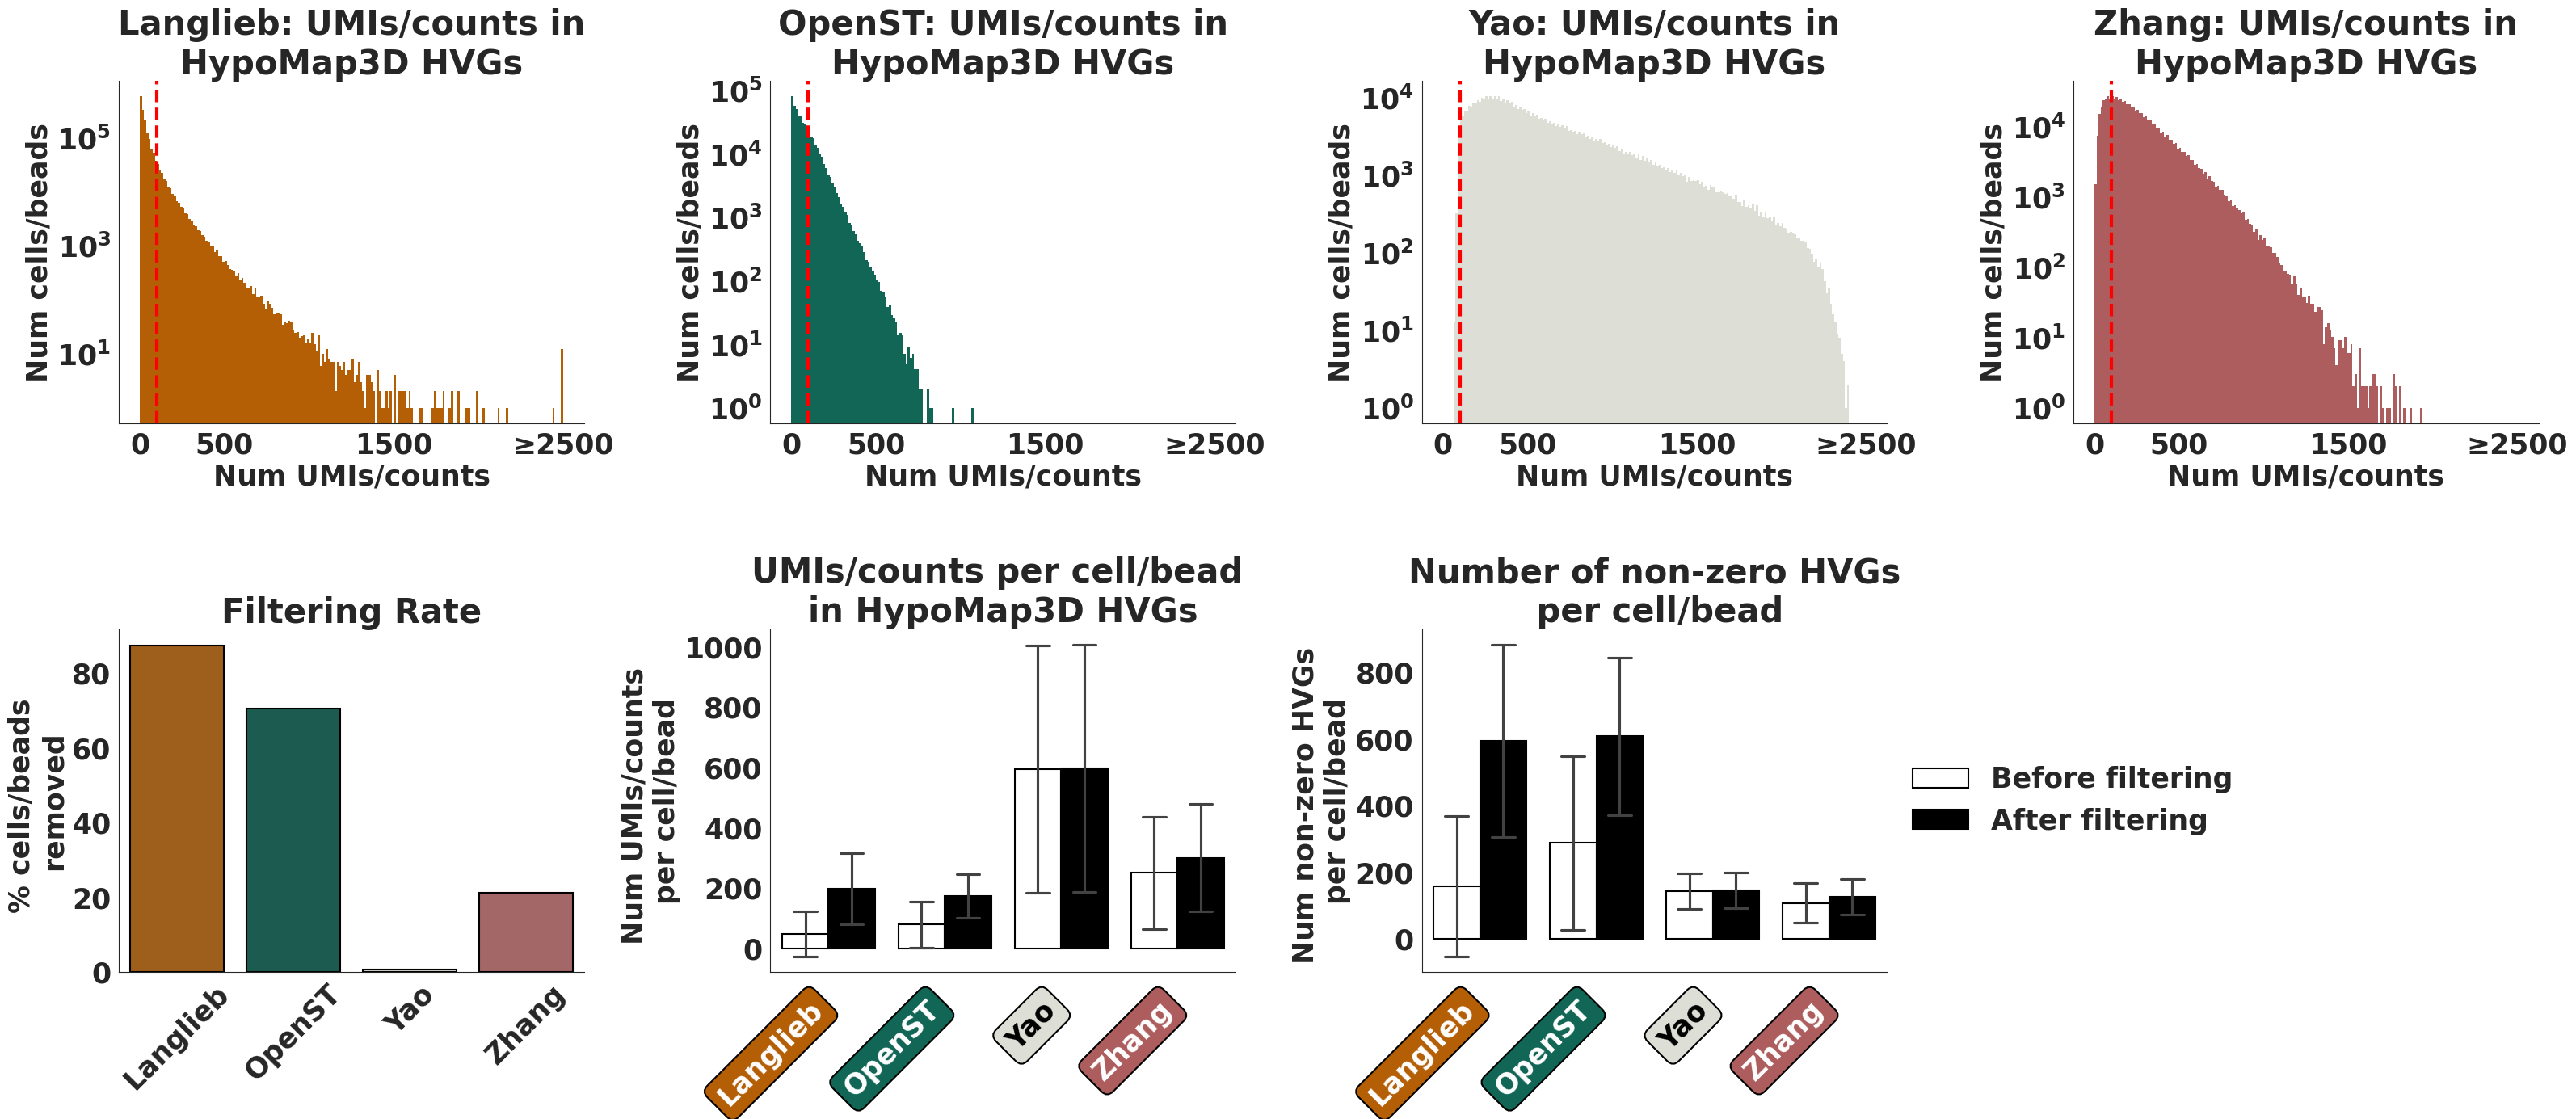

In [68]:
# Copy the data
df = hm_hvgs_df.copy()

# Desired author order
author_order = ["Langlieb", "OpenST", "Yao", "Zhang"]

# Font settings
FONT_SIZE_TITLE = 30
FONT_SIZE_LABEL = 25
FONT_SIZE_TICKS = 25

# Set up figure with 2 rows and 4 columns (4 histograms, 3 bar plots + 1 empty)
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(32, 14))

# === Row 1: Histograms (per author) ===
for i, author in enumerate(author_order):
    ax = axes[0][i]
    subset = df[df["author"] == author]

    # Cap all values above 2500 into the last bin
    data_capped = subset["total_hvg_counts"].clip(upper=2500)

    # Define bin edges from 0 to 2500 with 200 bins
    bins = np.linspace(0, 2500, 201)  # 200 bins means 201 edges

    ax.hist(
        data_capped,
        bins=bins,
        histtype="bar",
        rwidth=1.0,
        color=st_author_colors[author],
        edgecolor="none",
    )


    ax.axvline(x=100, color="red", linestyle="--", linewidth=3)
    ax.set_yscale("log")

    ax.set_title(f"{author}: UMIs/counts in\nHypoMap3D HVGs", fontsize=FONT_SIZE_TITLE, fontweight="bold")
    ax.set_xlabel("Num UMIs/counts", fontsize=FONT_SIZE_LABEL, fontweight="bold")
    ax.set_ylabel("Num cells/beads", fontsize=FONT_SIZE_LABEL, fontweight="bold")

    ax.tick_params(axis='both', labelsize=FONT_SIZE_TICKS)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontweight("bold")

    # --- Custom ticks: 0, 500, 1500, 2500 (last shown as ≥2500) ---
    xticks = [0, 500, 1500, 2500]
    xtick_labels = ["0", "500", "1500", "≥2500"]

    ax.set_xticks(xticks)
    ax.set_xticklabels(xtick_labels)

    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontweight("bold")

# === Prepare data for second row ===
df_bar = pd.concat([
    df.assign(filtering="Before filtering"),
    df[df["total_hvg_counts"] >= 100].assign(filtering="After filtering")
])

# === Row 2, Col 1: % cells removed (<100 UMIs) ===
removal_df = (
    df.assign(removed=lambda d: d["total_hvg_counts"] < 100)
    .groupby("author")["removed"]
    .agg(["sum", "count"])
    .reset_index()
)
removal_df["percent_removed"] = 100 * removal_df["sum"] / removal_df["count"]
removal_df = removal_df.set_index("author").loc[author_order].reset_index()

ax = axes[1][0]
bar_colors = [st_author_colors[author] for author in author_order]

barplot = sns.barplot(
    data=removal_df,
    x="author",
    y="percent_removed",
    palette=bar_colors,
    ax=ax
)

for bar in barplot.patches:
    bar.set_edgecolor("black")
    bar.set_linewidth(1.5)

ax.set_ylabel("% cells/beads \nremoved", fontsize=FONT_SIZE_LABEL, fontweight="bold")
ax.set_xlabel("", fontsize=FONT_SIZE_LABEL, fontweight="bold")
ax.set_title("Filtering Rate", fontsize=FONT_SIZE_TITLE, fontweight="bold")

ax.tick_params(axis="x", labelsize=FONT_SIZE_TICKS)
ax.tick_params(axis="y", labelsize=FONT_SIZE_TICKS)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45)
for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_fontweight("bold")


# === Row 2, Col 2: Barplot of mean UMIs + SEM ===
ax = axes[1][1]
barplot = sns.barplot(
    data=df_bar,
    x="author",
    y="total_hvg_counts",
    hue="filtering",
    hue_order=["Before filtering", "After filtering"],
    order=author_order,
    palette=["white", "black"],
    ax=ax,
    errorbar="sd",
    capsize=.4
)

for bar in barplot.patches:
    bar.set_edgecolor("black")
    bar.set_linewidth(1.5)

ax.set_ylabel("Num UMIs/counts \nper cell/bead", fontsize=FONT_SIZE_LABEL, fontweight="bold")
ax.set_xlabel("", fontsize=FONT_SIZE_LABEL, fontweight="bold")
ax.set_title("UMIs/counts per cell/bead \nin HypoMap3D HVGs", fontsize=FONT_SIZE_TITLE, fontweight="bold")

ax.tick_params(axis="x", labelsize=FONT_SIZE_TICKS)
ax.tick_params(axis="y", labelsize=FONT_SIZE_TICKS)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45)
for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_fontweight("bold")

# === Remove legend from UMIs plot ===
ax.legend_.remove()

# Hide default xticks
ax.set_xticklabels([])

# Draw custom rotated labels with color-coded boxes
for tick, author in enumerate(author_order):
    font_color = "white" if author != "Yao" else "black"
    ax.text(
        tick, -0.07, author,
        ha='right',
        va='top',
        fontsize=FONT_SIZE_TICKS,
        fontweight='bold',
        color=font_color,
        rotation=45,
        bbox=dict(
            facecolor=st_author_colors[author],
            edgecolor='black',
            boxstyle='round,pad=0.3',
            linewidth=1.5
        ),
        transform=ax.get_xaxis_transform()
    )



# === Row 2, Col 3: Barplot of mean nonzero genes + SEM ===
ax = axes[1][2]
barplot = sns.barplot(
    data=df_bar,
    x="author",
    y="total_genes",
    hue="filtering",
    hue_order=["Before filtering", "After filtering"],
    order=author_order,
    palette=["white", "black"],
    ax=ax,
    errorbar="sd",
    capsize=.4
)

for bar in barplot.patches:
    bar.set_edgecolor("black")
    bar.set_linewidth(1.5)

ax.set_ylabel("Num non-zero HVGs \nper cell/bead", fontsize=FONT_SIZE_LABEL, fontweight="bold")
ax.set_xlabel("", fontsize=FONT_SIZE_LABEL, fontweight="bold")
ax.set_title("Number of non-zero HVGs\n per cell/bead", fontsize=FONT_SIZE_TITLE, fontweight="bold")

ax.tick_params(axis="x", labelsize=FONT_SIZE_TICKS)
ax.tick_params(axis="y", labelsize=FONT_SIZE_TICKS)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45)
for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_fontweight("bold")

# Hide default xticks
ax.set_xticklabels([])

# Draw custom rotated labels with color-coded boxes
for tick, author in enumerate(author_order):
    font_color = "white" if author != "Yao" else "black"
    ax.text(
        tick, -0.07, author,
        ha='right',
        va='top',
        fontsize=FONT_SIZE_TICKS,
        fontweight='bold',
        color=font_color,
        rotation=45,
        bbox=dict(
            facecolor=st_author_colors[author],
            edgecolor='black',
            boxstyle='round,pad=0.3',
            linewidth=1.5
        ),
        transform=ax.get_xaxis_transform()
    )




# === Move legend to the right of the gene plot ===
legend = ax.legend(
    #title="Filtering",
    title_fontsize=FONT_SIZE_LABEL,
    fontsize=FONT_SIZE_TICKS,
    frameon=False,
    loc='center left',
    bbox_to_anchor=(1, 0.5)
)
# Bold legend labels
for text in legend.get_texts():
    text.set_fontweight("bold")
    
# === Hide unused subplot (bottom right) ===
axes[1][3].axis("off")

# === Final layout tweaks ===
sns.despine()
plt.tight_layout()
plt.subplots_adjust(hspace=0.6, wspace=0.4)

fig.savefig(OUTDIR / "ST_gene_count_filtering.pdf", dpi=300, bbox_inches="tight")

plt.show()

In [ ]:
hm_hvgs_df.to_csv(OUTDIR / "ST_gene_count_filtering_data.csv")

## Confidences

##

In [ ]:
levels = [f"L{i}" for i in range(1,6)]
max_p_cols = [f"{level}_max_p" for level in levels]
conf_dfs = []
for author, adata in adata_dict.items():

    before_df = adata.obs.loc[:, max_p_cols]
    before_df = pd.melt(before_df, var_name="Level", value_name="Confidence")
    before_df["author"] = author
    before_df["filtering_status"] = "Before filtering"
    conf_dfs.append(before_df)

    after_df = adata.obs.loc[~adata.obs.GetsFiltered, max_p_cols]
    after_df = pd.melt(after_df, var_name="Level", value_name="Confidence")
    after_df["author"] = author
    after_df["filtering_status"] = "After filtering"
    conf_dfs.append(after_df)

conf_data = pd.concat(conf_dfs)
conf_data.Level = conf_data.Level.apply(lambda x: x.split("_")[0])

In [ ]:
conf_data.head()

,Level,Confidence,author,filtering_status
0,L1,0.992757,Yao,Before filtering
1,L1,0.974606,Yao,Before filtering
2,L1,0.697312,Yao,Before filtering
3,L1,0.908010,Yao,Before filtering
4,L1,0.982046,Yao,Before filtering


In [15]:
conf_data.to_csv(OUTDIR / "confidences_filtering_data.csv", index=False)

In [46]:
conf_data = pd.read_csv(OUTDIR / "confidences_filtering_data.csv")

In [48]:
big_fontsize = 24  # Huge font size for ticks, labels, and legend
bigger_fontsize = 30

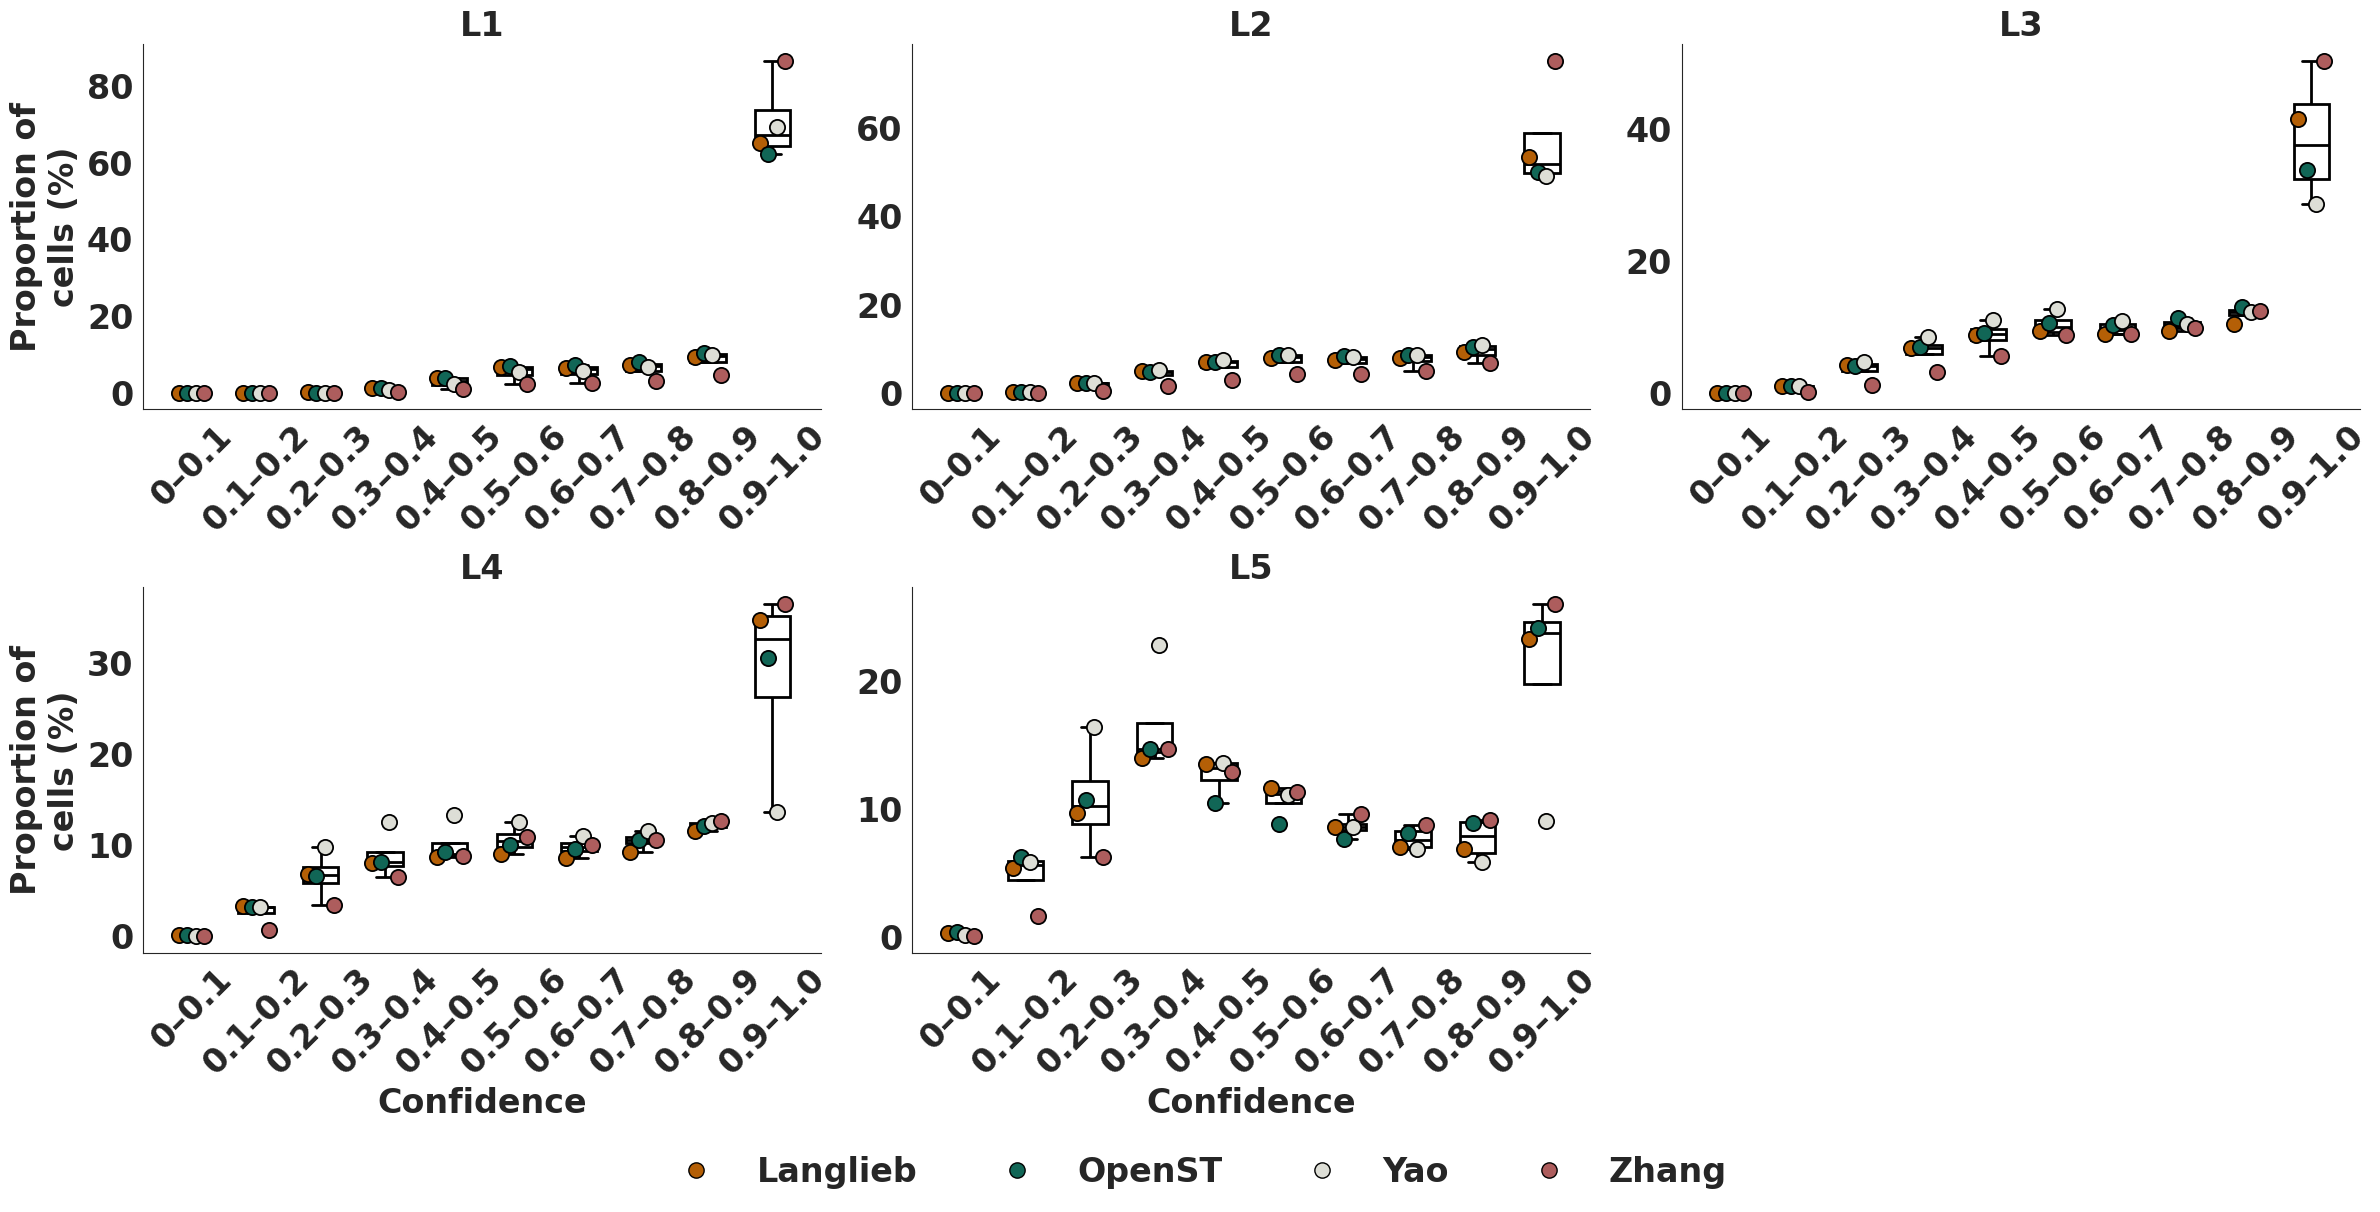

In [66]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

# ============================================================
# Settings
# ============================================================

bins = np.arange(0, 1.01, 0.1)
#bin_labels = [f"{bins[i]:.1f}" for i in range(len(bins)-1)]
bin_labels = [
    "0–0.1",
    "0.1–0.2",
    "0.2–0.3",
    "0.3–0.4",
    "0.4–0.5",
    "0.5–0.6",
    "0.6–0.7",
    "0.7–0.8",
    "0.8–0.9",
    "0.9–1.0",
]

# bins = np.arange(0, 1.25, 0.25)
# bin_labels = [
#     "0–0.25",
#     "0.25–0.5",
#     "0.5–0.75",
#     "0.75–1.0",
# ]

# bins = np.arange(0, 1.2, 0.2)
#bin_labels = [f"{bins[i]:.1f}–{bins[i+1]:.1f}" for i in range(len(bins)-1)]




# ------------------------------------------------------------
# Confidence distribution summary (AFTER FILTERING ONLY)
# ------------------------------------------------------------

dist_summary = (
    conf_data[conf_data["filtering_status"] == "After filtering"]
    .assign(
        bin=lambda x: pd.cut(
            x["Confidence"],
            bins=bins,
            labels=bin_labels,
            include_lowest=True,
        )
    )
)

dist_summary = (
    dist_summary
    .groupby(["author", "Level", "bin"], observed=True)
    .size()
    .rename("count")
    .reset_index()
)

dist_summary["percent"] = (
    dist_summary
    .groupby(["author", "Level"])["count"]
    .transform(lambda x: x / x.sum() * 100)
)

authors = sorted(dist_summary.author.unique())
levels = sorted(dist_summary.Level.unique())

# Ensure every author has every bin
idx = pd.MultiIndex.from_product(
    [authors, levels, bin_labels],
    names=["author", "Level", "bin"]
)

dist_summary = (
    dist_summary
    .set_index(["author", "Level", "bin"])
    .reindex(idx, fill_value=0)
    .reset_index()
)

# ------------------------------------------------------------
# High-confidence summary (>0.5)
# ------------------------------------------------------------

high_summary = (
    conf_data[conf_data["filtering_status"] == "After filtering"]
    .assign(high=lambda x: x["Confidence"] > 0.5)
    .groupby(["author", "Level"])["high"]
    .mean()
    .mul(100)
    .reset_index(name="percent")
)

# ============================================================
# Figure
# ============================================================

fig, axes = plt.subplots(
    2,
    3,
    figsize=(24, 12),
    sharey=False,
)

# Mapping levels to subplot positions
level_axes = {
    levels[0]: axes[0, 0],
    levels[1]: axes[0, 1],
    levels[2]: axes[0, 2],
    levels[3]: axes[1, 0],
    levels[4]: axes[1, 1],
}

axes[1, 2].remove()

# ============================================================
# Shared offsets for author dots
# ============================================================

offsets = np.linspace(-0.20, 0.20, len(authors))
author_offsets = dict(zip(authors, offsets))

# ============================================================
# Panels A-E
# ============================================================

for level in levels:

    ax = level_axes[level]

    subset = dist_summary[dist_summary["Level"] == level]

    sns.boxplot(
        data=subset,
        x="bin",
        y="percent",
        order=bin_labels,
        color="white",
        linewidth=2,
        linecolor="black",
        width=0.55,
        fliersize=0,
        ax=ax,
    )

    # # ---------- OPTIONAL: connect author profiles ----------
    # for author in authors:

    #     author_data = (
    #         subset[subset["author"] == author]
    #         .set_index("bin")
    #         .loc[bin_labels]
    #     )

    #     ax.plot(
    #         np.arange(len(bin_labels)),
    #         author_data["percent"],
    #         color=st_author_colors[author],
    #         alpha=0.35,
    #         linewidth=1.5,
    #         zorder=2,
    #     )

    # ---------- author dots ----------
    for i, b in enumerate(bin_labels):

        for author in authors:

            value = subset[
                (subset["author"] == author)
                & (subset["bin"] == b)
            ]["percent"].iloc[0]

            ax.scatter(
                i + author_offsets[author],
                value,
                s=120,
                color=st_author_colors[author],
                edgecolor="black",
                linewidth=1.3,
                zorder=3,
            )

    ax.set_title(
        level,
        fontsize=big_fontsize,
        fontweight="bold",
    )

    ax.set_xlabel(
        "Confidence",
        fontsize=big_fontsize,
        fontweight="bold",
    )

    ax.tick_params(axis="both", labelsize=big_fontsize)

    for tick in ax.get_xticklabels():
        tick.set_rotation(45)
        tick.set_fontweight("bold")

    for tick in ax.get_yticklabels():
        tick.set_fontweight("bold")

    ticks = np.arange(len(bin_labels))
    # labels = [
    #     lab if i % 2 == 0 else ""
    #     for i, lab in enumerate(bin_labels)
    # ]
    labels = bin_labels

    ax.set_xticks(ticks)
    ax.set_xticklabels(labels)

    sns.despine(ax=ax)

    if ax not in (axes[0, 0], axes[1, 0]):
        ax.set_ylabel("")
    if ax not in (axes[1, 0], axes[1, 1], axes[1, 2]):
        ax.set_xlabel("")

# Left-column y-labels only
axes[0,0].set_ylabel(
    "Proportion of\ncells (%)",
    fontsize=big_fontsize,
    fontweight="bold",
)

axes[1,0].set_ylabel(
    "Proportion of\ncells (%)",
    fontsize=big_fontsize,
    fontweight="bold",
)



# ============================================================
# Shared legend
# ============================================================

author_handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="",
        markersize=11,
        markerfacecolor=st_author_colors[a],
        markeredgecolor="black",
        label=a,
    )
    for a in authors
]

legend = fig.legend(
    handles=author_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.02),
    ncol=len(authors),
    frameon=False,
    fontsize=big_fontsize,
)

for text in legend.get_texts():
    text.set_fontweight("bold")

# ============================================================
# Layout
# ============================================================

fig.tight_layout(rect=[0, 0.05, 1, 1])

fig.savefig(
    OUTDIR / "ST_confidence_summary_combined_bar.pdf",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

### aggregated, only cells that were kept

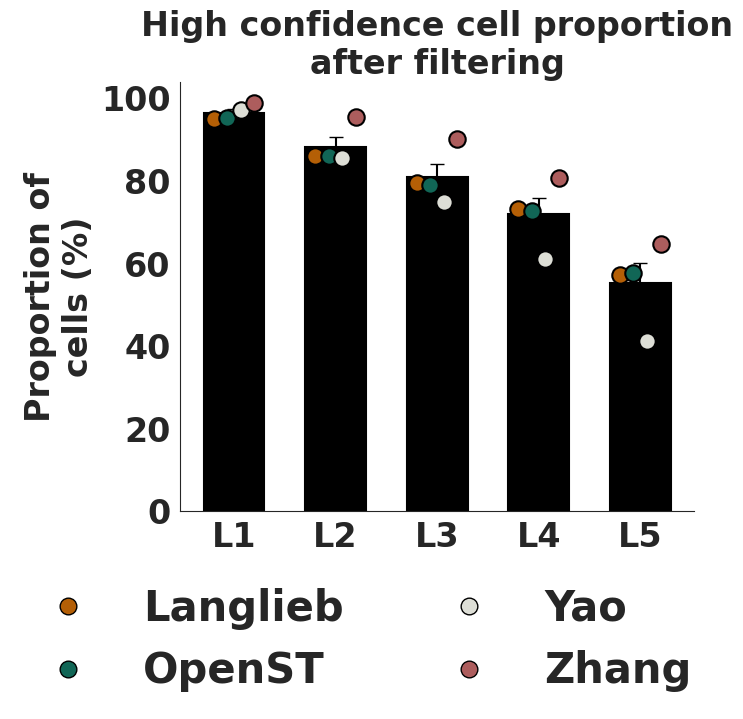

In [54]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

# ------------------------------------------------------------------
# Percentage of high-confidence cells (After filtering only)
# ------------------------------------------------------------------
summary = (
    conf_data[conf_data["filtering_status"] == "After filtering"]
    .assign(high=lambda x: x["Confidence"] > 0.5)
    .groupby(["author", "Level"])["high"]
    .mean()
    .mul(100)
    .reset_index(name="percent")
)

levels = sorted(summary["Level"].unique())
authors = sorted(summary["author"].unique())

fig, ax = plt.subplots(figsize=(7, 7))

# ------------------------------------------------------------------
# Bar plot: mean ± SEM across authors
# ------------------------------------------------------------------

summary_stats = (
    summary
    .groupby("Level")["percent"]
    .agg(["mean", "sem"])
    .reindex(levels)
    .reset_index()
)

ax.bar(
    np.arange(len(levels)),
    summary_stats["mean"],
    yerr=summary_stats["sem"],
    color="black",
    edgecolor="black",
    linewidth=1.5,
    capsize=5,
    width=0.6,
    zorder=1,
)
# ------------------------------------------------------------------
# Overlay author points
# ------------------------------------------------------------------
# Fixed horizontal offsets (deterministic jitter)
offsets = np.linspace(-0.2, 0.2, len(authors))
author_offsets = dict(zip(authors, offsets))

for i, level in enumerate(levels):

    for author in authors:

        value = summary[
            (summary["Level"] == level)
            & (summary["author"] == author)
        ]["percent"].iloc[0]

        ax.scatter(
            i + author_offsets[author],
            value,
            s=140,
            color=st_author_colors[author],
            edgecolor="black",
            linewidth=1.5,
            zorder=3,
        )

# ------------------------------------------------------------------
# Formatting
# ------------------------------------------------------------------
ax.set_xlabel("")
ax.set_ylabel(
    "Proportion of\ncells (%)",
    fontsize=big_fontsize,
    fontweight="bold",
)

ax.set_xticks(np.arange(len(levels)))
ax.set_xticklabels(levels)

ax.set_ylim(bottom=0)

ax.tick_params(axis="both", labelsize=big_fontsize)

for tick in ax.get_xticklabels() + ax.get_yticklabels():
    tick.set_fontweight("bold")

sns.despine(ax=ax)

# ------------------------------------------------------------------
# Author legend (below plot)
# ------------------------------------------------------------------
author_handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="",
        markersize=12,
        markerfacecolor=st_author_colors[a],
        markeredgecolor="black",
        label=a,
    )
    for a in authors
]

legend = fig.legend(
    handles=author_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.15),
    ncol=2,
    frameon=False,
    fontsize=bigger_fontsize,
)

for text in legend.get_texts():
    text.set_fontweight("bold")

ax.set_title("High confidence cell proportion\nafter filtering", 
    fontsize=big_fontsize, fontweight="bold")

fig.tight_layout(rect=[0, 0.08, 1, 0.9])

fig.savefig(
    OUTDIR / "ST_high_confidence_barplot_after_filtering.pdf",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## Number of clusters detected with at least n high confidence cells 

In [19]:
adata_st = sc.read_h5ad(SC_ST_FP, backed="r")

In [21]:
adata_st.obs.Author = adata_st.obs.Author.replace({"Bauder": "OpenST"})

In [22]:

counts_list=[]
rpc_list = []
rpa_list = []

for level in [f"L{i}" for i in range(1,6)]:

    # Column names
    cluster_col = f"{level}_descr_max_p"
    prob_col = f"{level}_max_p"

    # Keep only confident assignments
    filtered = adata_st[adata_st.obs[prob_col] > 0.5].obs.copy()

    # Count cells per Author x Cluster
    counts = (
        filtered
        .groupby(["Author", cluster_col])
        .size()
        .unstack(fill_value=0)
        .T
    )

    # Set names
    counts.index.name = "Cluster"
    counts.columns.name = "Author"

    # Calculate fraction of each cluster contributed by each author
    ratios_per_cluster = counts.div(counts.sum(axis=1), axis=0)

    # Calculate author ratios per cluster
    # (fraction of each author's confidently assigned cells belonging to each cluster)
    ratios_per_author = counts.div(counts.sum(axis=0), axis=1)

    # indicate whetehr cluster has been detected by merging the datasets
    counts["Combined"] = counts.sum(axis=1)

    ratios_per_cluster = ratios_per_cluster.loc[counts.index]
    ratios_per_author = ratios_per_author.loc[counts.index]

    counts["level"] = level
    ratios_per_cluster["level"] = level
    ratios_per_author["level"] = level

    counts_list.append(counts)
    rpc_list.append(ratios_per_cluster)
    rpa_list.append(ratios_per_author)

counts=pd.concat(counts_list, axis=0)
ratios_per_cluster=pd.concat(rpc_list, axis=0)
ratios_per_author=pd.concat(rpa_list, axis=0)

In [24]:
min_num_cells = 1

detected_clusters = counts.loc[:, [c for c in counts if c != "level"]] >= min_num_cells 
detected_clusters["level"] = counts["level"]


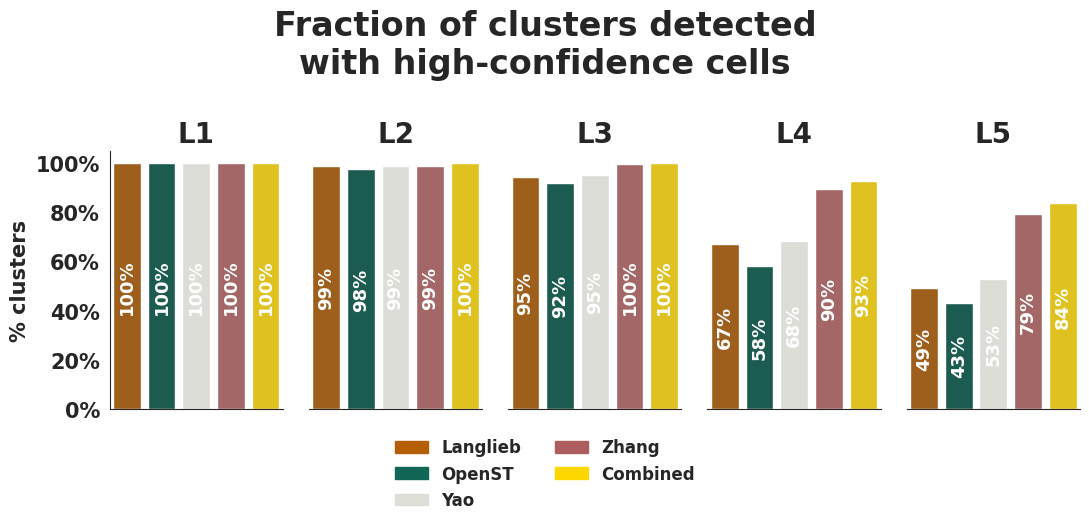

In [53]:
# -----------------------------
# Font size variables (same as before)
# -----------------------------
FIG_TITLE_FONTSIZE = 24
TITLE_FONTSIZE = 20
AXISLABEL_FONTSIZE = 15
AXISTICK_FONTSIZE = 15
ANNOT_FONTSIZE = 13
LEGEND_FONTSIZE = 12
# -----------------------------

author_cols = sorted(
    [c for c in detected_clusters.columns if c not in ["level", "Combined"]]
) + ["Combined"]

level_totals = {
    "L1": len(adata_st.uns["L1_descr"]),
    "L2": len(adata_st.uns["L2_descr"]),
    "L3": len(adata_st.uns["L3_descr"]),
    "L4": len(adata_st.uns["L4_descr"]),
    "L5": len(adata_st.uns["L5_descr"]),
}

plot_df = (
    detected_clusters
    .groupby("level")[author_cols]
    .sum()                       # number of detected clusters (True = 1)
    .reset_index()
)

plot_df["total_clusters"] = plot_df["level"].map(level_totals)

for author in author_cols:
    plot_df[author] = plot_df[author] / plot_df["total_clusters"]

plot_df = plot_df.melt(
    id_vars="level",
    var_name="author",
    value_name="ratio"
)

plot_df["pct"] = (100 * plot_df["ratio"]).round().astype(int)

plot_df=plot_df.loc[plot_df.author != "total_clusters"]

sns.set_style("white")

levels = sorted(plot_df["level"].unique(), key=lambda x: int(x[1:]))

fig, axes = plt.subplots(
    1,
    len(levels),
    figsize=(2.2 * len(levels), 5),
    sharey=True
)

for i, level in enumerate(levels):

    ax = axes[i]

    subset = plot_df.query("level == @level")

    sns.barplot(
        data=subset,
        x="author",
        y="ratio",
        order=author_cols,
        palette=st_author_colors,
        ax=ax
    )

    for j, (_, row) in enumerate(subset.iterrows()):
        ax.text(
            j,
            row["ratio"] / 2,
            f"{row['pct']}%",
            color="white",
            ha="center",
            va="center",
            rotation=90,
            fontweight="bold",
            fontsize=ANNOT_FONTSIZE,
        )
    ax.set_title(level,
                 fontsize=TITLE_FONTSIZE,
                 fontweight="bold")

    ax.set_xlabel("")

    if i == 0:
        ax.set_ylabel(
            "% clusters",
            fontsize=AXISLABEL_FONTSIZE,
            fontweight="bold",
        )
        ax.yaxis.set_major_formatter(
            mticker.PercentFormatter(xmax=1)
        )
        ax.tick_params(axis="y",
                       labelsize=AXISTICK_FONTSIZE)

        for label in ax.get_yticklabels():
            label.set_fontweight("bold")
    else:
        ax.set_ylabel("")
        ax.yaxis.set_visible(False)
        ax.spines["left"].set_visible(False)


    ax.set_ylim(0, 1.05)

    sns.despine(ax=ax, left=(i != 0))
    ax.set_xlabel("")
    ax.set_xticks([])

author_patches = [
    mpatches.Patch(
        color=st_author_colors[author],
        label=author
    )
    for author in author_cols
]
legend = fig.legend(
    handles=author_patches,
    loc="lower center",
    ncol=2,
    frameon=False,
    fontsize=LEGEND_FONTSIZE,
    bbox_to_anchor=(0.5, -0.01)
)

for text in legend.get_texts():
    text.set_fontweight("bold")

fig.suptitle(
    "Fraction of clusters detected\nwith high-confidence cells",
    fontsize=FIG_TITLE_FONTSIZE,
    fontweight="bold",
    y=1.02,
)

fig.tight_layout(rect=[0, 0.05, 1, 1])

plt.subplots_adjust(
    bottom=0.22,
    wspace=0.15,
)

plt.savefig(
    OUTDIR / "detected_clusters_ratio.pdf",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## distribution of cells along AP

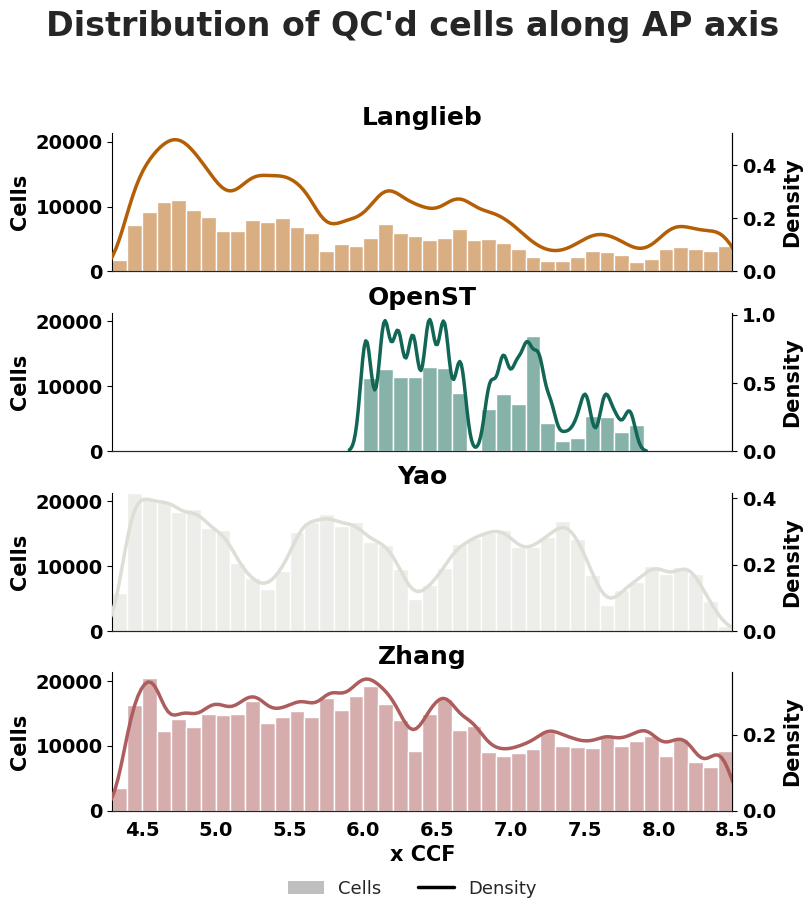

In [62]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# -----------------------------
# Font size variables
# -----------------------------
TITLE_FONTSIZE = 18
AXISLABEL_FONTSIZE = 15
AXISTICK_FONTSIZE = 14
# -----------------------------

# Build plotting dataframe
plot_df = adata_st.obs[["Author"]].copy()
plot_df["x_ccf"] = adata_st.obsm["coords_ccf_mm"]["x"]

authors = sorted(
    set(st_author_colors.keys()).intersection(plot_df["Author"].unique())
)

# Common x/y limits
xmin = plot_df["x_ccf"].min()
xmax = plot_df["x_ccf"].max()

# Histogram bins every 0.1 mm
bins = np.arange(
    np.floor(xmin * 10) / 10,
    np.ceil(xmax * 10) / 10 + 0.1,
    0.1,
)

# Determine common histogram y-limit
ymax_hist = 0
for author in authors:
    vals = plot_df.loc[plot_df["Author"] == author, "x_ccf"]
    hist, _ = np.histogram(vals, bins=bins)
    ymax_hist = max(ymax_hist, hist.max())

fig, axes = plt.subplots(
    len(authors),
    1,
    figsize=(8, 2.2 * len(authors)),
    sharex=True,
)
fig.subplots_adjust(hspace=0.3)

if len(authors) == 1:
    axes = [axes]

for ax, author in zip(axes, authors):

    vals = plot_df.loc[plot_df["Author"] == author, "x_ccf"]

    # Left axis: histogram (counts)
    sns.histplot(
        vals,
        bins=bins,
        stat="count",
        color=st_author_colors[author],
        alpha=0.5,
        edgecolor=None,
        ax=ax,
    )

    ax.set_ylim(0, ymax_hist)
    ax.set_ylabel(
        "Cells",
        fontsize=AXISLABEL_FONTSIZE,
        fontweight="bold",
    )

    # Right axis: KDE (density)
    ax2 = ax.twinx()

    sns.kdeplot(
        vals,
        color=st_author_colors[author],
        linewidth=2.5,
        bw_adjust=0.8,
        ax=ax2,
    )

    ax2.set_ylabel(
        "Density",
        fontsize=AXISLABEL_FONTSIZE,
        fontweight="bold",
    )

    # Left axis (histogram)
    ax.set_ylabel(
        "Cells",
        fontsize=AXISLABEL_FONTSIZE,
        fontweight="bold",
        color="black",
    )

    ax.tick_params(
        axis="y",
        colors="black",
        labelsize=AXISTICK_FONTSIZE,
    )

    ax.spines["left"].set_color("black")

    # Right axis (KDE)
    ax2.set_ylabel(
        "Density",
        fontsize=AXISLABEL_FONTSIZE,
        fontweight="bold",
        color="black",
    )

    ax2.tick_params(
        axis="y",
        colors="black",
        labelsize=AXISTICK_FONTSIZE,
    )


    # x axis
    ax.set_xlabel(
        "x CCF",
        fontsize=AXISLABEL_FONTSIZE,
        fontweight="bold",
        color="black",
    )

    ax.tick_params(
        axis="x",
        colors="black",
        labelsize=AXISTICK_FONTSIZE,
    )

    ax2.spines["right"].set_color("black")

    for label in ax.get_xticklabels():
        label.set_fontweight("bold")

    for label in ax.get_yticklabels():
        label.set_fontweight("bold")

    for label in ax2.get_yticklabels():
        label.set_fontweight("bold")

    ax.set_title(
        author,
        fontsize=TITLE_FONTSIZE,
        fontweight="bold",
        color="black",#st_author_colors[author],
    )

    ax.set_xlim(bins.min(), bins.max())

    sns.despine(ax=ax, right=False)
    sns.despine(ax=ax2, left=True, right=False)

    ax2.tick_params(
        axis="y",
        right=True,
        labelright=True,
    )

legend_handles = [
    Patch(facecolor="gray", edgecolor="none", alpha=0.5, label="Cells"),
    Line2D([0], [0], color="black", lw=2.5, label="Density"),
]

fig.legend(
    handles=legend_handles,
    loc="upper center",
    ncol=2,
    frameon=False,
    fontsize=13,
    bbox_to_anchor=(0.5, 0.05),
)

fig.suptitle(
    "Distribution of QC'd cells along AP axis",
    fontsize=FIG_TITLE_FONTSIZE,
    fontweight="bold",
    y=1.02,
)


plt.savefig(
    OUTDIR / "cells_along_ap_all_authors.pdf",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
